# Task 2: Adversarial Search - Tank Battle Game Experiments

This notebook evaluates and compares the four required adversarial search configurations:
1. **Minimax Search**
2. **Alpha-Beta Search**
3. **Heuristic Minimax Search**
4. **Heuristic Minimax with Alpha-Beta Pruning**

In [1]:
from agents.minimax_agent import MinimaxAgent
from main import run_four_configurations_experiment, simulate_match
import matplotlib.pyplot as plt

depths = [2, 3, 4, 5]
results = run_four_configurations_experiment(depths)

Configuration                       | Depth |  Explored States |     Time (s) | Action    
----------------------------------------------------------------------------------------
Minimax Search                      |     2 |               12 |     0.000132 | FIRE      
Alpha-Beta Search                   |     2 |                8 |     0.000094 | FIRE      
Heuristic Minimax Search            |     2 |               12 |     0.000101 | MOVE_UP   
Heuristic Minimax with Alpha-Beta   |     2 |               10 |     0.000095 | MOVE_UP   
----------------------------------------------------------------------------------------
Minimax Search                      |     3 |               48 |     0.000310 | FIRE      
Alpha-Beta Search                   |     3 |               22 |     0.000175 | FIRE      
Heuristic Minimax Search            |     3 |               48 |     0.000355 | MOVE_UP   
Heuristic Minimax with Alpha-Beta   |     3 |               35 |     0.000306 | MOVE_UP   
---

In [2]:
matchups = [
    (MinimaxAgent(1, depth=3, use_alpha_beta=False, use_heuristic=True),
     MinimaxAgent(2, depth=3, use_alpha_beta=False, use_heuristic=False)),
    (MinimaxAgent(1, depth=3, use_alpha_beta=True, use_heuristic=True),
     MinimaxAgent(2, depth=3, use_alpha_beta=True, use_heuristic=False)),
    (MinimaxAgent(1, depth=3, use_alpha_beta=True, use_heuristic=True),
     MinimaxAgent(2, depth=3, use_alpha_beta=False, use_heuristic=True)),
]

for a1, a2 in matchups:
    m = simulate_match(a1, a2, max_turns=80)
    print(m)

Player 1 (MAX)                    vs Player 2 (MIN)                    | Winner | Turns | P1 Avg States | P2 Avg States
--------------------------------------------------------------------------------------------------------------------
Heuristic Minimax Search          vs Minimax Search                    |     P1 |    32 |         150.8 |         118.6
Heuristic Minimax with Alpha-Beta vs Alpha-Beta Search                 |     P1 |    32 |          51.2 |          32.9
Heuristic Minimax with Alpha-Beta vs Heuristic Minimax Search          |     P2 |    33 |          48.5 |         203.6


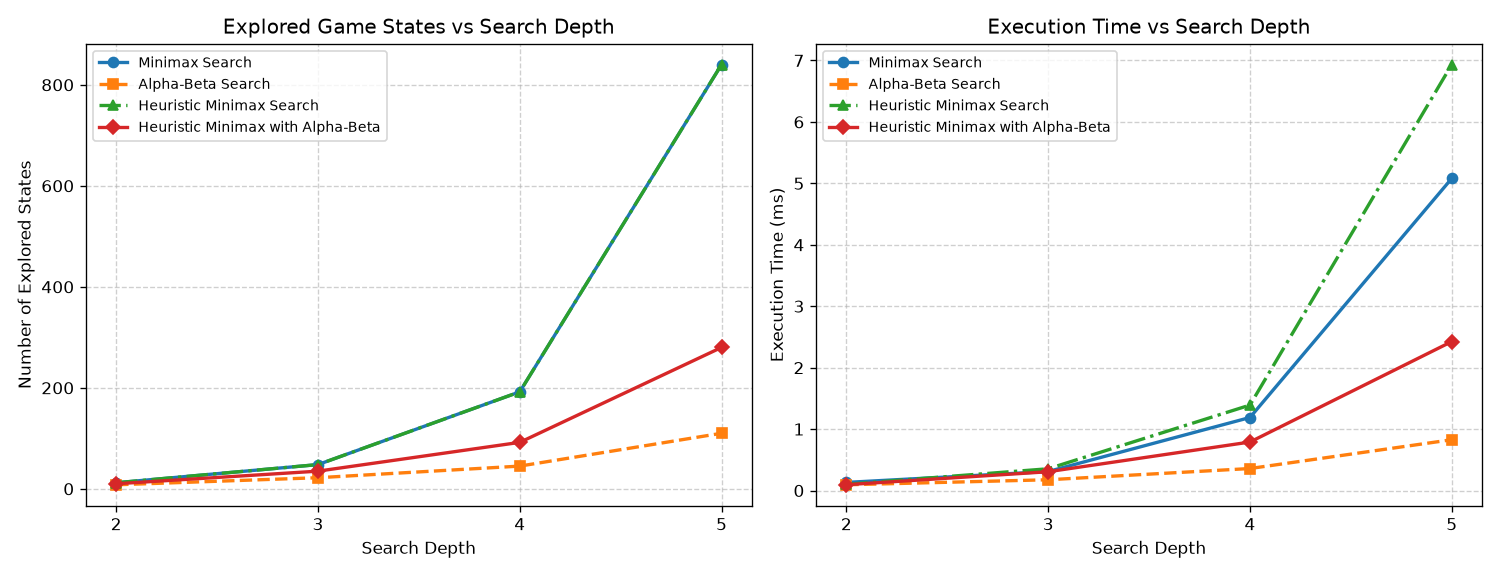

In [3]:
configs = [
    'Minimax Search',
    'Alpha-Beta Search',
    'Heuristic Minimax Search',
    'Heuristic Minimax with Alpha-Beta',
]
markers = ['o', 's', '^', 'D']
styles = ['-', '--', '-.', '-']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
for cfg, mk, st in zip(configs, markers, styles):
    cfg_rows = [r for r in results if r['config'] == cfg]
    ds = [r['depth'] for r in cfg_rows]
    st_cnt = [r['explored_states'] for r in cfg_rows]
    tms = [r['time'] * 1000.0 for r in cfg_rows]
    ax1.plot(ds, st_cnt, marker=mk, linestyle=st, linewidth=2, label=cfg)
    ax2.plot(ds, tms, marker=mk, linestyle=st, linewidth=2, label=cfg)

ax1.set_title('Explored Game States vs Search Depth')
ax1.set_xlabel('Search Depth')
ax1.set_ylabel('Number of Explored States')
ax1.set_xticks(depths)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=8.5)

ax2.set_title('Execution Time vs Search Depth')
ax2.set_xlabel('Search Depth')
ax2.set_ylabel('Execution Time (ms)')
ax2.set_xticks(depths)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig('tank_experiments.png', dpi=150)
plt.show()